# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary. 

##### Technical Respose
Used Car Dealership wanted to know which features of the vehicle such as year, manufacturer, model, condition, cylinders, fuel, odometer, title_status, transmission, drive, size, type, paint_color, state etc. contribute the vehicle price the most. The data set contains all these features and the appropriate model will be created and visualized to identify the most influential features that affect the vehicle price the most. The final report will be provided to the Used Car Dealership, so that they can make the decision to keep the best inventory and boost their sales revenue.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

##### Technical Respose
First step is to understand the data. For this, load the dataset into the dataframe first and review the dataframe structure for the below.
1) Total rows
2) How many Columns and their data types
3) Which are the Feature columns and the Target column
4) The relevant and selected columns have good quality data or not
5) If there is data quality issue such as missing value, unusable value, out of range data etc., plan the steps to cleanse them
6) Plan the steps needed to Encode the Categorical data into the Numerical equivalent.
7) Also, Scale the data since Categorical and Numerical Features' values will not be comparable without Scaling

In [22]:
# Install the Libraries
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [23]:
# Import the Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [24]:
vehicle_original_df = pd.read_csv("data/vehicles.csv") # Load the dataset
vehicle_original_df.info() # Display information about the dataset
vehicle_original_df.head() # Display the first few rows of the dataset

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  str    
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  str    
 5   model         421603 non-null  str    
 6   condition     252776 non-null  str    
 7   cylinders     249202 non-null  str    
 8   fuel          423867 non-null  str    
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  str    
 11  transmission  424324 non-null  str    
 12  VIN           265838 non-null  str    
 13  drive         296313 non-null  str    
 14  size          120519 non-null  str    
 15  type          334022 non-null  str    
 16  paint_color   296677 non-null  str    
 17  state         426880 non-null  str    
dtypes: float64(2), 

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


Original Data Set:

1) There are total 426,880 rows in the Original Used Vehicles data set.
2) 18 Columns are: id, region, price, year, manufacturer, model, condition, cylinders, fuel, odometer, title_status, transmission, VIN, drive,
size, type, paint_color and state.
3) price is the Target (Prediction) column
4) Remaining Columns are Feature columns

In [28]:
# Get distinct values in each column
for column in vehicle_original_df.columns:
    distinct_values = vehicle_original_df[column].nunique()
    print(f"Column '{column}' has {distinct_values} distinct values.")

# Get each Categorical column's distinct values, excluding 'region' and 'VIN' columns, and limit the 'model' column to first 20 distinct values
for column in vehicle_original_df.columns:
    if vehicle_original_df[column].dtype == 'str':
        if column == 'model':
            unique_values = vehicle_original_df[column].unique()[:20]  # Limit to first 20 distinct values for 'model'
        elif column in ['region', 'VIN']:
            pass
        else:
            unique_values = vehicle_original_df[column].unique()
        print(f"\n\nDistinct values in column '{column}': {unique_values}")

# Get the number of missing values in each column
print(f"\n\nNumber of missing values in each column:")
print(vehicle_original_df.isna().sum())

# Get the min and max values of the numerical columns, except for 'id' column, which is an identifier and not a feature
print(f"\n\nMin and max values for numerical columns:")
for column in vehicle_original_df.columns:
    if vehicle_original_df[column].dtype in ['int64', 'float64']:
        if column != 'id':  # Exclude the 'id' column
            print(f"Column '{column}' has min value: {vehicle_original_df[column].min()} and max value: {vehicle_original_df[column].max()}")

Column 'id' has 426880 distinct values.
Column 'region' has 404 distinct values.
Column 'price' has 15655 distinct values.
Column 'year' has 114 distinct values.
Column 'manufacturer' has 42 distinct values.
Column 'model' has 29649 distinct values.
Column 'condition' has 6 distinct values.
Column 'cylinders' has 8 distinct values.
Column 'fuel' has 5 distinct values.
Column 'odometer' has 104870 distinct values.
Column 'title_status' has 6 distinct values.
Column 'transmission' has 3 distinct values.
Column 'VIN' has 118246 distinct values.
Column 'drive' has 3 distinct values.
Column 'size' has 4 distinct values.
Column 'type' has 13 distinct values.
Column 'paint_color' has 12 distinct values.
Column 'state' has 51 distinct values.


Distinct values in column 'region': <StringArray>
['az', 'ar', 'fl', 'ma', 'nc', 'ny', 'or', 'pa', 'tx', 'wa', 'wi', 'al', 'ak',
 'ca', 'co', 'ct', 'dc', 'de', 'ga', 'hi', 'id', 'il', 'in', 'ia', 'ks', 'ky',
 'la', 'me', 'md', 'mi', 'mn', 'ms', 'mo', 'm

Below columns will be discarded in the Modeling:

1) id - This is to identify the record and is a Primary/Unique key
2) region - This categorical column has many distinct values. Instead 'state' column will be used
3) model - This categorical column has many distinct unclean and unusable values and will be discarded. Insteade 'manufacturer' column will be used
4) VIN - This is to identify the vehicle

Missing Values Columns in the Original dataset are - year, manufacturer, model, condition, cylinders, fuel, odometer, title_status, transmission, VIN, drive, size, type and paint_color.

Selected Categorical columns with missing values will be filled with the value 'unknown'.
Rows for Numerical columns (year and odometer) with missing values will be dropped.
Rows for Numerical column (price) with value less than $1,000 and greater than $100,000 will be dropped to eliminate the noise.

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

In [30]:
# Remove the columns that are not needed for analysis
# id - It's unique for each vehicle and does not provide any useful information for analysis.
# region - It will be discarded. Instead 'state' column can be used for analysis.
# model - Most values are not clean and will be discarded. Instead 'manufacturer' column can be used for analysis.
# VIN - It is unique for each vehicle and does not provide any useful information for analysis.
vehicle_cleansed_df = vehicle_original_df.drop(['id', 'region', 'model', 'VIN'], axis=1, inplace=False)

# Update the missing values to 'unknown' for categorical columns
vehicle_cleansed_df[vehicle_cleansed_df.select_dtypes(exclude=['number']).columns] = vehicle_cleansed_df.select_dtypes(exclude=['number']).fillna('unknown')

# Remove the rows where year is missing, as it is an important feature for predicting the price of a vehicle
vehicle_cleansed_df = vehicle_cleansed_df[vehicle_cleansed_df['year'].notna()]

# Remove the rows where odometer is missing, as it is an important feature for predicting the price of a vehicle
vehicle_cleansed_df = vehicle_cleansed_df[vehicle_cleansed_df['odometer'].notna()]

# Remove the rows where price is less than $1,000 and greater than $100,000, as they are noisy data points and can skew the analysis
# The price of a vehicle is an important feature for predicting the price of a vehicle, and these extreme values can affect the accuracy of the model.
vehicle_cleansed_df = vehicle_cleansed_df[(vehicle_cleansed_df['price'] >= 1000) & (vehicle_cleansed_df['price'] <= 100000)]

# Deduplicate the rows based on all columns and keep the first occurrence of each duplicate
vehicle_cleansed_df = vehicle_cleansed_df.drop_duplicates(keep='first')

# Validation - Get the number of missing values in each column
# There should be no missing values in the dataset after cleansing
print("Number of missing values in each column, after cleansing:")
print(vehicle_cleansed_df.isna().sum())

# Print the Total number of rows
print("\n\nTotal number of rows in the dataset, after cleansing: ", len(vehicle_cleansed_df))

# Reindex the dataframe after removing rows
vehicle_cleansed_df.reset_index(drop=True, inplace=True)

# Convert the year column to integer type
vehicle_cleansed_df['year'] = vehicle_cleansed_df['year'].apply(lambda x: int(x))

# Convert the odometer column to integer type
vehicle_cleansed_df['odometer'] = vehicle_cleansed_df['odometer'].apply(lambda x: int(x))

vehicle_cleansed_df.info() # Display information about the cleansed dataset
vehicle_cleansed_df.head() # Display the first few rows of the cleansed dataset

Number of missing values in each column, after cleansing:
price           0
year            0
manufacturer    0
condition       0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
size            0
type            0
paint_color     0
state           0
dtype: int64


Total number of rows in the dataset, after cleansing:  266260
<class 'pandas.DataFrame'>
RangeIndex: 266260 entries, 0 to 266259
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   price         266260 non-null  int64
 1   year          266260 non-null  int64
 2   manufacturer  266260 non-null  str  
 3   condition     266260 non-null  str  
 4   cylinders     266260 non-null  str  
 5   fuel          266260 non-null  str  
 6   odometer      266260 non-null  int64
 7   title_status  266260 non-null  str  
 8   transmission  266260 non-null  str  
 9   drive         266260 non-null  str  
 10  size

,price,year,manufacturer,condition,cylinders,fuel,odometer,title_status,transmission,drive,size,type,paint_color,state
0,33590,2014,gmc,good,8 cylinders,gas,57923,clean,other,unknown,unknown,pickup,white,al
1,22590,2010,chevrolet,good,8 cylinders,gas,71229,clean,other,unknown,unknown,pickup,blue,al
2,39590,2020,chevrolet,good,8 cylinders,gas,19160,clean,other,unknown,unknown,pickup,red,al
3,30990,2017,toyota,good,8 cylinders,gas,41124,clean,other,unknown,unknown,pickup,red,al
4,15000,2013,ford,excellent,6 cylinders,gas,128000,clean,automatic,rwd,full-size,truck,black,al


Cleansed Data Set:

There are total 266,260 rows in the Cleansed Used Vehicles data set.

14 Columns are: price, year, manufacturer, condition, cylinders, fuel, odometer, title_status, transmission, drive,
size, type, paint_color and state.

### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

RMSE: 10826.93
MAE: 7149.11
R²: 0.40
CV R² Scores: [0.39509108 0.40736754 0.4038664  0.41087725 0.40294475 0.40317629]


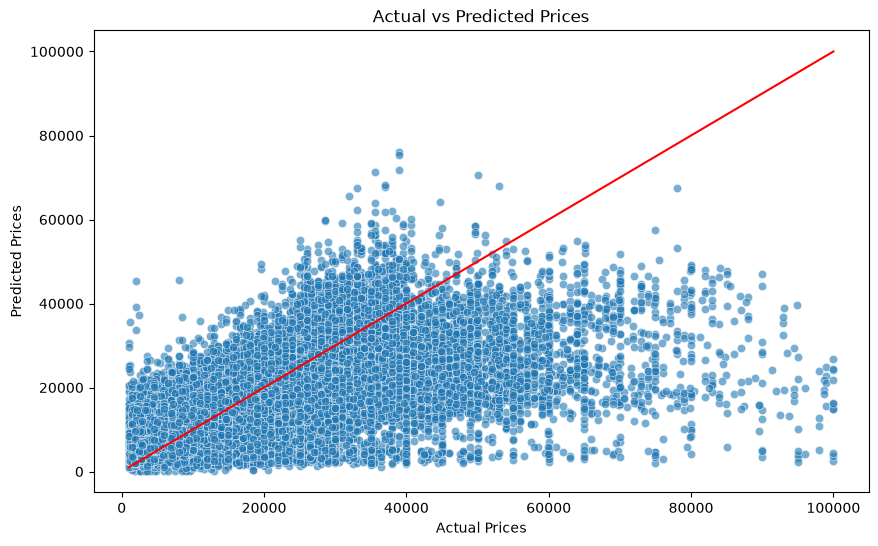

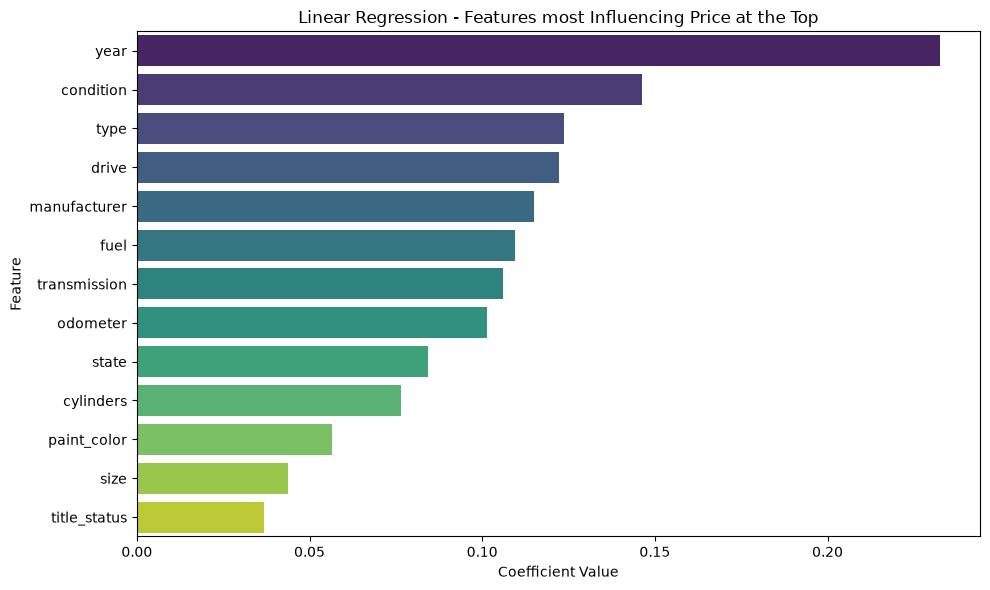

In [36]:
# Create Linear Regression Model from the vehicle_cleansed_df dataset where price column is the target and the remaining columns are the features

# Define X (features) and y (target)
categorical_cols = ['manufacturer', 'fuel', 'condition', 'cylinders', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color', 'state']
numerical_cols = ['odometer', 'year']

X = vehicle_cleansed_df[categorical_cols + numerical_cols] # Data Frame for Features
# odometer and price are inversely correlated, which means that as the odometer value increases, the price of the vehicle decreases.
# To make the relationship between odometer and price more intuitive, we can multiply the odometer column by -1. This way, higher inverted odometer values will correspond to lower prices, which is more interpretable.
# year and price are positively correlated, which means that as the year of the vehicle increases, the price of the vehicle also increases. This is because newer vehicles are generally more expensive than older vehicles. So, we can keep year as is.
X['odometer'] *= -1
y = vehicle_cleansed_df["price"] # Series for Target
y = np.log(y) # Log-transform the target variable to stabilize variance and make the data more normally distributed

# Split into train and test sets (80/20 split). shuffle=True means random split. random_state=42 is used for reproducibility of results.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

# KFold Cross Validation is used to avoid data leakage and overfitting. The number of splits is set to 6, which means that the dataset will be split into 6 folds, and each fold will be used as a validation set once while the remaining 5 folds will be used for training. The random_state is set to 42 for reproducibility of results.
# Setup Target Encoder for Categorical features. Target is 'price' which is a continuous variable.
# Remainder of the columns will be passed through without any transformation, which are the numerical columns in this case.
cv_strategy = KFold(n_splits=6, shuffle=True, random_state=42) # shuffle=True means random split
preprocessor = ColumnTransformer(
    transformers=[
        (
            "target_encoder",
            TargetEncoder(target_type="continuous", categories='auto', smooth='auto', cv=cv_strategy, random_state=42),
            categorical_cols,
        )
    ],
    remainder="passthrough"
)

# Create Pipeline with Preprocessing, Scaling and Linear Regression
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),  # Scaling is important to ensure that all features are on the same scale
        ("regressor", LinearRegression())
    ]
)

# Grid Search Hyperparameters (e.g., fit_intercept for LinearRegression)
param_grid = {"regressor__fit_intercept": [True, False]}
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="r2",
)
grid_search.fit(X_train, y_train)

# Evaluate Model on Test Set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

y_train = np.exp(y_train) # Convert actual values back to original scale
y_test = np.exp(y_test)  # Convert actual values back to original scale
y_pred = np.exp(y_pred)  # Convert predictions back to original scale

# Below 3 are the Evaluation Metrics used for the Model
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.2f}")

# Cross-Validation Stability Check
cv_scores = cross_val_score(
    estimator=best_model, X=X_train, y=y_train, cv=cv_strategy, scoring="r2"
)
print(f"CV R² Scores: {cv_scores}")

# Plot Actual vs. Predicted Values using Seaborn
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.show()

# Coefficient Interpretation
coefficients_df = pd.DataFrame({
    'Feature': [name.split('__')[-1] for name in list(best_model.named_steps['preprocessor'].get_feature_names_out())],
    'Coefficient': best_model.named_steps['regressor'].coef_
})

# Plot coefficients using Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(
    data=coefficients_df.sort_values(by='Coefficient', ascending=False),
    x='Coefficient', y='Feature', palette='viridis'
)
plt.title('Linear Regression - Features most Influencing Price at the Top')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Linear Regression:

Root Mean Sqaure Error: 10826.93 (High number indicates the Model Accuracy is lower)

Mean Absolute Error: 7149.11 (High number indicates the Model Accuracy is lower)

R² Score: 0.40 (40% of the variation in the outcome is predictable from the input features)

Cross Validation R² Scores: [0.39509108 0.40736754 0.4038664  0.41087725 0.40294475 0.40317629]

It tells how well the machine learning model generalizes to unseen data. A score 1.0 means Perfect Prediction whereas 0.0 means Poor Prediction. Each of the 6 Cross Validations has score around 0.40 (or 40%) which tells the Prediction is somewhat better than a baseline model that simply predicts the mean value of the data.

Top 3 Features most affected the Vehicle Price are Year, Condition and Type in that order.

RMSE: 10827.51
MAE: 7149.49
R²: 0.40
CV R² scores: [0.39509838 0.40736516 0.40386658 0.41087575 0.40294907 0.40317202]


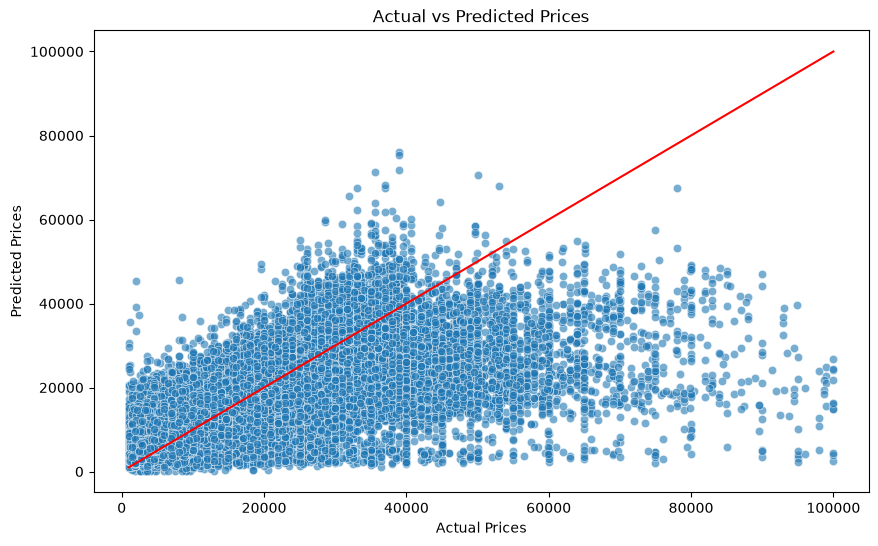

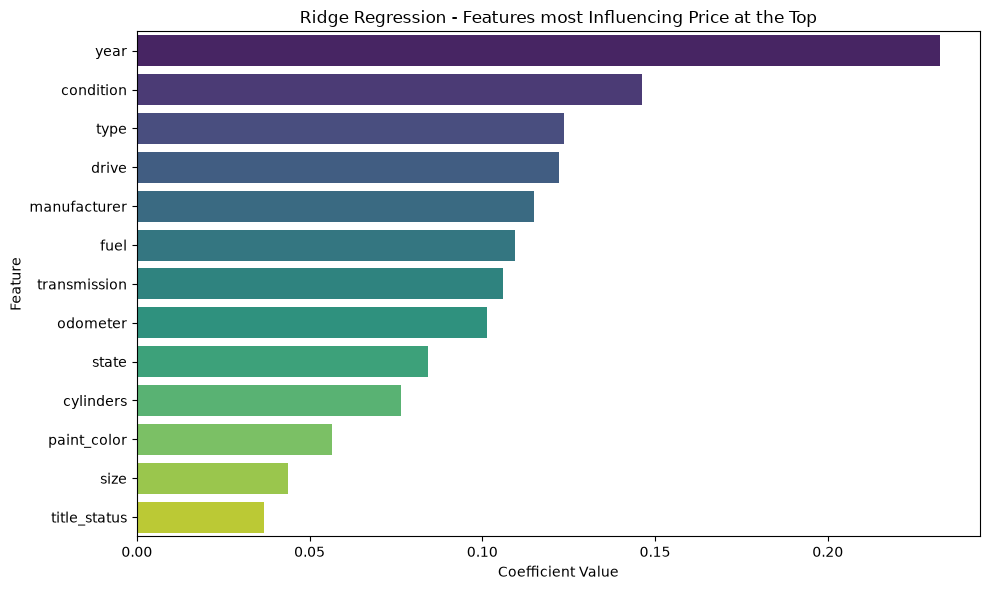

In [37]:
# Create Ridge Regression Model from the vehicle_cleansed_df dataset where price column is the target and the remaining columns are the features

# Define X (features) and y (target)
categorical_cols = ['manufacturer', 'fuel', 'condition', 'cylinders', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color', 'state']
numerical_cols = ['odometer', 'year']

X = vehicle_cleansed_df[categorical_cols + numerical_cols] # Data Frame for Features
# odometer and price are inversely correlated, which means that as the odometer value increases, the price of the vehicle decreases.
# To make the relationship between odometer and price more intuitive, we can multiply the odometer column by -1. This way, higher inverted odometer values will correspond to lower prices, which is more interpretable.
# year and price are positively correlated, which means that as the year of the vehicle increases, the price of the vehicle also increases. This is because newer vehicles are generally more expensive than older vehicles. So, we can keep year as is.
X['odometer'] *= -1
y = vehicle_cleansed_df["price"] # Series for Target
y = np.log(y) # Log-transform the target variable to stabilize variance and make the data more normally distributed

# Split into train and test sets (80/20 split). shuffle=True means random split. random_state=42 is used for reproducibility of results.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

# KFold Cross Validation is used to avoid data leakage and overfitting. The number of splits is set to 6, which means that the dataset will be split into 6 folds, and each fold will be used as a validation set once while the remaining 5 folds will be used for training. The random_state is set to 42 for reproducibility of results.
# Setup Target Encoder for Categorical features. Target is 'price' which is a continuous variable.
# Remainder of the columns will be passed through without any transformation, which are the numerical columns in this case.
cv_strategy = KFold(n_splits=6, shuffle=True, random_state=42) # shuffle=True means random split
preprocessor = ColumnTransformer(
    transformers=[
        (
            "target_encoder",
            TargetEncoder(target_type="continuous", categories='auto', smooth='auto', cv=cv_strategy, random_state=42),
            categorical_cols,
        )
    ],
    remainder="passthrough"
)

# Create Pipeline with Preprocessing, Scaling and Ridge Regression
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),  # Scaling is important to ensure that all features are on the same scale
        ("regressor", Ridge())
    ]
)

# Grid Search Hyperparameters (e.g., alpha for Ridge Regression)
param_grid = {'regressor__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="r2",
)
grid_search.fit(X_train, y_train)

# Evaluate Model on Test Set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

y_train = np.exp(y_train) # Convert actual values back to original scale
y_test = np.exp(y_test)  # Convert actual values back to original scale
y_pred = np.exp(y_pred)  # Convert predictions back to original scale

# Below 3 are the Evaluartion Metrics used for the Model
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.2f}")

# Cross-Validation Stability Check
cv_scores = cross_val_score(
    estimator=best_model, X=X_train, y=y_train, cv=cv_strategy, scoring="r2"
)
print(f"CV R² scores: {cv_scores}")

# Plot Actual vs. Predicted Values using Seaborn
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.show()

# Coefficient Interpretation
coefficients_df = pd.DataFrame({
    'Feature': [name.split('__')[-1] for name in list(best_model.named_steps['preprocessor'].get_feature_names_out())],
    'Coefficient': best_model.named_steps['regressor'].coef_
})

# Plot coefficients using Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(
    data=coefficients_df.sort_values(by='Coefficient', ascending=False),
    x='Coefficient', y='Feature', palette='viridis'
)
plt.title('Ridge Regression - Features most Influencing Price at the Top')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Ridge Regression:

Root Mean Sqaure Error: 10827.51 (High number indicates the Model Accuracy is lower)

Mean Absolute Error: 7149.49 (High number indicates the Model Accuracy is lower)

R² Score: 0.40 (40% of the variation in the outcome is predictable from the input features)

Cross Validation R² Scores: [0.39509838 0.40736516 0.40386658 0.41087575 0.40294907 0.40317202]

It tells how well the machine learning model generalizes to unseen data. A score 1.0 means Perfect Prediction whereas 0.0 means Poor Prediction. Each of the 6 Cross Validations has score around 0.40 (or 40%) which tells the Prediction is somewhat better than a baseline model that simply predicts the mean value of the data.

Top 3 Features most affected the Vehicle Price are Year, Condition, and Type in that order.

RMSE: 10833.81
MAE: 7152.63
R²: 0.40
CV R² Scores: [0.39509108 0.40736753 0.4038664  0.41087725 0.40294476 0.40317628]


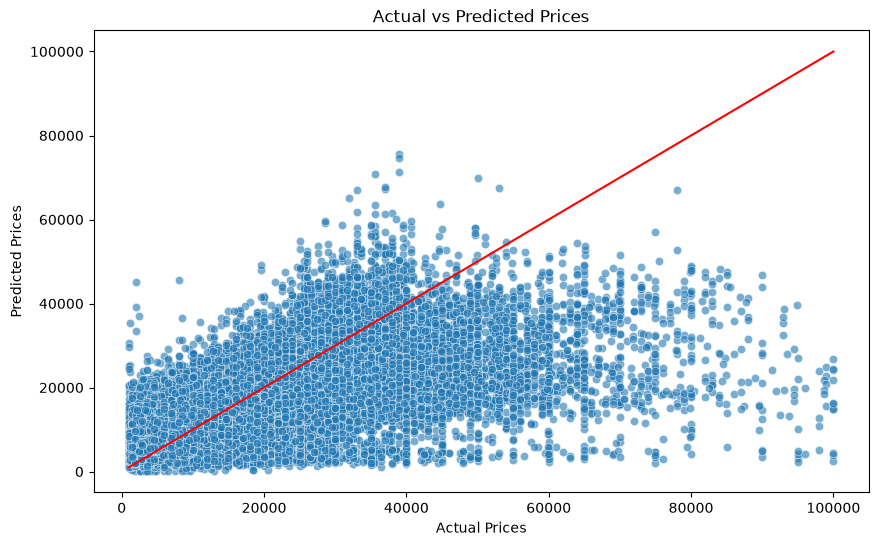

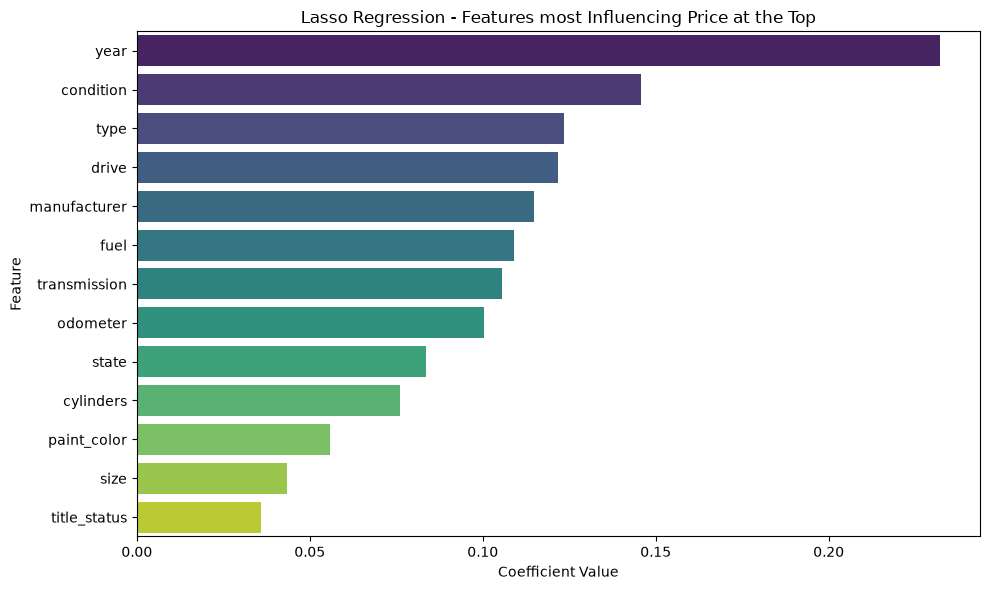

In [38]:
# Create Lasso Regression Model from the vehicle_cleansed_df dataset where price column is the target and the remaining columns are the features

# Define X (features) and y (target)
categorical_cols = ['manufacturer', 'fuel', 'condition', 'cylinders', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color', 'state']
numerical_cols = ['odometer', 'year']

X = vehicle_cleansed_df[categorical_cols + numerical_cols] # Data Frame for Features
# odometer and price are inversely correlated, which means that as the odometer value increases, the price of the vehicle decreases.
# To make the relationship between odometer and price more intuitive, we can multiply the odometer column by -1. This way, higher inverted odometer values will correspond to lower prices, which is more interpretable.
# year and price are positively correlated, which means that as the year of the vehicle increases, the price of the vehicle also increases. This is because newer vehicles are generally more expensive than older vehicles. So, we can keep year as is.
X['odometer'] *= -1
y = vehicle_cleansed_df["price"] # Series for Target
y = np.log(y) # Log-transform the target variable to stabilize variance and make the data more normally distributed

# Split into train and test sets (80/20 split). shuffle=True means random split. random_state=42 is used for reproducibility of results.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

# KFold Cross Validation is used to avoid data leakage and overfitting. The number of splits is set to 6, which means that the dataset will be split into 6 folds, and each fold will be used as a validation set once while the remaining 5 folds will be used for training. The random_state is set to 42 for reproducibility of results.
# Setup Target Encoder for Categorical features. Target is 'price' which is a continuous variable.
# Remainder of the columns will be passed through without any transformation, which are the numerical columns in this case.
cv_strategy = KFold(n_splits=6, shuffle=True, random_state=42) # shuffle=True means random split
preprocessor = ColumnTransformer(
    transformers=[
        (
            "target_encoder",
            TargetEncoder(target_type="continuous", categories='auto', smooth='auto', cv=cv_strategy, random_state=42),
            categorical_cols,
        )
    ],
    remainder="passthrough"
)

# Create Pipeline with Preprocessing, Scaling and Lasso Regression
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),  # Lasso requires scaled features; Scaling is important to ensure that all features are on the same scale
        ("regressor", Lasso(random_state=42))
    ]
)

# Grid Search Hyperparameters (e.g., alpha for Lasso Regression)
param_grid = {"regressor__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="r2",
)
grid_search.fit(X_train, y_train)

# Evaluate Model on Test Set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

y_train = np.exp(y_train) # Convert actual values back to original scale
y_test = np.exp(y_test)  # Convert actual values back to original scale
y_pred = np.exp(y_pred)  # Convert predictions back to original scale

# Below 3 are the Evaluartion Metrics used for the Model
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.2f}")

# Cross-Validation Stability Check
cv_scores = cross_val_score(
    estimator=best_model, X=X_train, y=y_train, cv=cv_strategy, scoring="r2"
)
print(f"CV R² Scores: {cv_scores}")

# Plot Actual vs. Predicted Values using Seaborn
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.show()

# Coefficient Interpretation
coefficients_df = pd.DataFrame({
    'Feature': [name.split('__')[-1] for name in list(best_model.named_steps['preprocessor'].get_feature_names_out())],
    'Coefficient': best_model.named_steps['regressor'].coef_
})

# Plot coefficients using Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(
    data=coefficients_df.sort_values(by='Coefficient', ascending=False),
    x='Coefficient', y='Feature', palette='viridis'
)
plt.title('Lasso Regression - Features most Influencing Price at the Top')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Lasso Regression:

Root Mean Sqaure Error: 10833.81 (High number indicates the Model Accuracy is lower)

Mean Absolute Error: 7152.63 (High number indicates the Model Accuracy is lower)

R² Score: 0.40 (40% of the variation in the outcome is predictable from the input features)

Cross Validation R² Scores: [0.39509108 0.40736753 0.4038664  0.41087725 0.40294476 0.40317628]

It tells how well the machine learning model generalizes to unseen data. A score 1.0 means Perfect Prediction whereas 0.0 means Poor Prediction. Each of the 6 Cross Validations has score around 0.40 (or 40%) which tells the Prediction is somewhat better than a baseline model that simply predicts the mean value of the data.

Top 3 Features most affected the Vehicle Price are Year, Condition, and Type in that order.

### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

Evaluation Report:

After analyzing all the 3 Regressions (Linear, Ridge and Lasso), it was found that Root Mean Sqaure Error (RMSE), Mean Absolute Error (MAE), R² Score, and Cross Validation R² Scores are identical in all those Models.

Also, all the 3 Models consistently agreed that the Top 3 Features most affected the Vehicle Price are Year, Condition and Type in that order.

### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

Client Report:

Top 3 Parameters that affect the Vehicle Price the most are Vehicle's Year of Manufacturing, Vehicle's Condition such as Excellent and Vehicle's Type such as SUV, Sedan etc. in that order. So, it is advised to source the vehicles with these top 3 parameters to boost the inventory and potentially maximize the Sales Volume and Revenue.